# GPT From Scratch Chatbot

This notebook builds a tiny GPT-style chatbot from scratch using PyTorch. It does not use BERT, Hugging Face models, or pretrained weights. It trains or loads a local BPE tokenizer from `tokenizer.json`, and writes tokenizer/model config files for future reuse.

## 1. Imports and Settings

This section loads all required libraries and defines the notebook-wide configuration values. The paths tell the notebook where to find the dataset, tokenizer files, model config files, and checkpoints. The training constants such as `BATCH_SIZE`, `BLOCK_SIZE`, `MAX_ITERS`, `LEARNING_RATE`, and `GRAD_CLIP` control how much text the model sees per step, how long each context window is, how long training runs, and how strongly gradients are clipped during backpropagation. The model constants define the tiny GPT architecture: embedding size, number of attention heads, number of transformer layers, and dropout rate. A fixed random seed is used so repeated runs are easier to compare.

In [92]:
import json
import math
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from tokenizers import Tokenizer
from tokenizers.decoders import ByteLevel as ByteLevelDecoder
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import ByteLevel
from tokenizers.trainers import BpeTrainer


if Path("chat_data.txt").exists():
    BASE_DIR = Path.cwd()
else:
    BASE_DIR = Path("/Users/abhishek/MLCourse/GenAI/gpt_from_scratch_chatbot")

CHAT_DATASET_DIR = BASE_DIR / "chat_dataset"
CONVERSATIONS_JSON_PATH = CHAT_DATASET_DIR / "greeting_conversations.json"
B_CONVERSATIONS_JSON_PATH = CHAT_DATASET_DIR / "basic_conversations.json"
CONVERSATION_JSON_PATHS = [CONVERSATIONS_JSON_PATH, B_CONVERSATIONS_JSON_PATH]
CHECKPOINT_DIR = BASE_DIR / "checkpoints"
CHECKPOINT_PATH = CHECKPOINT_DIR / "tiny_chatbot_combined.pt"
TOKENIZER_PATH = BASE_DIR / "tokenizer.json"
TOKENIZER_CONFIG_PATH = BASE_DIR / "tokenizer_config.json"
SPECIAL_TOKENS_MAP_PATH = BASE_DIR / "special_tokens_map.json"
MODEL_CONFIG_PATH = BASE_DIR / "model_config.json"
TOKENIZER_VOCAB_SIZE = 2000
SPECIAL_TOKENS = ["<pad>", "<unk>", "<user>", "<assistant>"]

BATCH_SIZE = 16
BLOCK_SIZE = 128
MAX_ITERS = 5000
EVAL_INTERVAL = 500
LEARNING_RATE = 3e-4
GRAD_CLIP = 1.0
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

N_EMBD = 128
N_HEAD = 4
N_LAYER = 4
DROPOUT = 0.1
SEED_NUMBER = 1001

torch.manual_seed(SEED_NUMBER)

DEVICE

'cpu'

## 2. Load Chat Data

This section builds the raw training text used by the language model from `chat_dataset/greeting_conversations.json` and `chat_dataset/basic_conversations.json`. These files are stored as JSONL, meaning each line is one JSON conversation record. The loader supports both this JSONL format and a normal JSON file, then converts each conversation into a chat-style transcript using `<user>:` and `<assistant>:` role markers. Those markers are important because the model learns the pattern of a user message followed by an assistant answer. The final combined text is lowercased so the tokenizer and model see a simpler, more consistent vocabulary.

In [93]:
def load_conversations_from_json(path):
    raw_text = path.read_text(encoding="utf-8-sig").strip()
    if not raw_text:
        return []

    try:
        dataset = json.loads(raw_text)
    except json.JSONDecodeError:
        dataset = [json.loads(line) for line in raw_text.splitlines() if line.strip()]

    if isinstance(dataset, dict) and "conversations" in dataset:
        records = dataset["conversations"]
    elif isinstance(dataset, list):
        records = dataset
    else:
        records = [dataset]

    conversations = []
    for record in records:
        conversation = record.get("conversation", record) if isinstance(record, dict) else {}
        messages = conversation.get("messages", []) if isinstance(conversation, dict) else []
        if messages:
            conversations.append({"messages": messages})
    return conversations


def load_text(file_paths=CONVERSATION_JSON_PATHS):
    if isinstance(file_paths, (str, Path)):
        file_paths = [Path(file_paths)]

    json_examples = []
    for file_path in file_paths:
        if not file_path.exists():
            raise FileNotFoundError(f"No dataset found at {file_path}")

        for conversation in load_conversations_from_json(file_path):
            lines = []
            for message in conversation.get("messages", []):
                role = message.get("role")
                content = message.get("content", "").strip()
                if role in {"user", "assistant"} and content:
                    lines.append(f"<{role}>: {content}")

            if lines:
                json_examples.append("\n".join(lines))

    if not json_examples:
        raise ValueError(f"No user/assistant messages found in {file_paths}")

    return "\n\n".join(json_examples).lower()


text = load_text(CONVERSATION_JSON_PATHS)

print("training dataset paths:")
for dataset_path in CONVERSATION_JSON_PATHS:
    print("-", dataset_path)
# print("human text path:", HUMAN_TEXT_PATH)
# print("robot text path:", ROBOT_TEXT_PATH)
print("characters:", len(text))
print(text[:500])

training dataset paths:
- /Users/abhishek/MLCourse/GenAI/gpt_from_scratch_chatbot/chat_dataset/greeting_conversations.json
- /Users/abhishek/MLCourse/GenAI/gpt_from_scratch_chatbot/chat_dataset/basic_conversations.json
characters: 204278808
<user>: hey please
<assistant>: absolutely. tell me what you want to work on. what would you like to learn today?

<user>: hi
<assistant>: hello! i'm here to help. share the problem and i'll help you solve it.

<user>: hello
<assistant>: hello! let's get started. i can help with coding, cloud, databases, ai, or general questions.

<user>: are you there
<assistant>: hello! i'm here to help.

<user>: hello assistant
<assistant>: nice to meet you too! how can i assist you? share the problem and i'l


## 3. Dataset Sentiment Check

This section performs a simple heuristic sentiment analysis on the merged JSONL datasets before training. Human text is taken from `role == "user"` messages, and robot text is taken from `role == "assistant"` messages in both `greeting_conversations.json` and `basic_conversations.json`. The sentiment check counts basic positive and negative words, buckets each line as positive, neutral, or negative, and plots the distributions side by side. This is not a production sentiment model; it is a quick dataset health check to understand whether the user and assistant text are mostly neutral, positive, or negative.

Counter({'neutral': 1913813, 'positive': 1086187}) Counter({'neutral': 1949505, 'positive': 1050495})


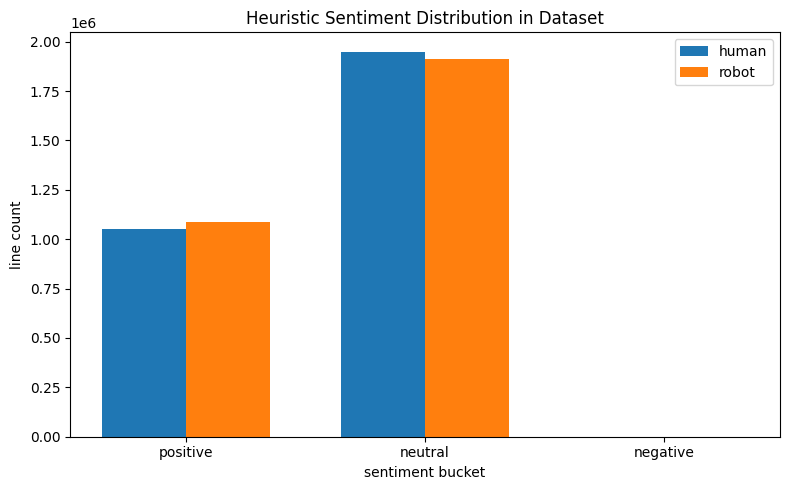

human sentiment: {'neutral': 1949505, 'positive': 1050495}
robot sentiment: {'positive': 1086187, 'neutral': 1913813}


In [94]:
positive_words = {
    "good", "great", "nice", "happy", "love", "like", "thanks", "thank",
    "fun", "smart", "cute", "friend", "beautiful", "interesting", "cool",
    "yes", "awesome", "best", "help", "helpful", "enjoy", "glad"
}

negative_words = {
    "bad", "sad", "sorry", "wrong", "hate", "suck", "dead", "weird",
    "slow", "problem", "angry", "no", "not", "can't", "cannot", "worse",
    "worst", "afraid", "fear", "hurt", "lonely"
}


def simple_sentiment_score(line):
    words = line.lower().replace(".", " ").replace("!", " ").replace("?", " ").split()
    positive = sum(word in positive_words for word in words)
    negative = sum(word in negative_words for word in words)
    return positive - negative


def sentiment_bucket(score):
    if score > 0:
        return "positive"
    if score < 0:
        return "negative"
    return "neutral"


def load_human_robot_lines_from_json(file_paths=CONVERSATION_JSON_PATHS):
    if isinstance(file_paths, (str, Path)):
        file_paths = [Path(file_paths)]

    human_lines = []
    robot_lines = []

    for file_path in file_paths:
        for conversation in load_conversations_from_json(file_path):
            for message in conversation.get("messages", []):
                role = message.get("role")
                content = message.get("content", "").strip()

                if not content:
                    continue
                if role == "user":
                    human_lines.append(content)
                elif role == "assistant":
                    robot_lines.append(content)

    return human_lines, robot_lines


human_lines, robot_lines = load_human_robot_lines_from_json(CONVERSATION_JSON_PATHS)

human_sentiment = Counter(
    sentiment_bucket(simple_sentiment_score(line))
    for line in human_lines
    if line.strip()
)
robot_sentiment = Counter(
    sentiment_bucket(simple_sentiment_score(line))
    for line in robot_lines
    if line.strip()
)
print(robot_sentiment, human_sentiment)
buckets = ["positive", "neutral", "negative"]
x = range(len(buckets))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar([i - width / 2 for i in x], [human_sentiment[b] for b in buckets], width=width, label="human")
plt.bar([i + width / 2 for i in x], [robot_sentiment[b] for b in buckets], width=width, label="robot")
plt.xticks(list(x), buckets)
plt.title("Heuristic Sentiment Distribution in Dataset")
plt.xlabel("sentiment bucket")
plt.ylabel("line count")
plt.legend()
plt.tight_layout()
plt.show()

print("human sentiment:", dict(human_sentiment))
print("robot sentiment:", dict(robot_sentiment))

## 4. Local BPE Tokenizer

This section trains or loads a local Byte Pair Encoding tokenizer. The tokenizer converts text into integer token IDs that the neural network can process, and it converts generated token IDs back into readable text. If `tokenizer.json` already exists, the notebook reuses it so training stays consistent across runs. If it does not exist or retraining is requested, the tokenizer is trained from the combined chat text. The helper also saves tokenizer and model configuration files so the chatbot can be loaded later without rebuilding everything manually.

In [95]:
def save_project_configs(vocab_size):
    TOKENIZER_CONFIG_PATH.write_text(
        json.dumps(
            {
                "tokenizer_class": "ByteLevelBPETokenizer",
                "tokenizer_file": TOKENIZER_PATH.name,
                "model_max_length": BLOCK_SIZE,
                "unk_token": "<unk>",
                "pad_token": "<pad>",
                "additional_special_tokens": ["<user>", "<assistant>"],
                "chat_template": "<user>: {user_message}\n<assistant>:",
            },
            indent=2,
        ) + "\n",
        encoding="utf-8",
    )

    SPECIAL_TOKENS_MAP_PATH.write_text(
        json.dumps(
            {
                "unk_token": "<unk>",
                "pad_token": "<pad>",
                "additional_special_tokens": ["<user>", "<assistant>"],
            },
            indent=2,
        ) + "\n",
        encoding="utf-8",
    )

    MODEL_CONFIG_PATH.write_text(
        json.dumps(
            {
                "model_type": "tiny_gpt_from_scratch",
                "vocab_size": vocab_size,
                "block_size": BLOCK_SIZE,
                "n_embd": N_EMBD,
                "n_head": N_HEAD,
                "n_layer": N_LAYER,
                "dropout": DROPOUT,
                "tokenizer_file": TOKENIZER_PATH.name,
                "checkpoint_file": str(CHECKPOINT_PATH.relative_to(BASE_DIR)),
            },
            indent=2,
        ) + "\n",
        encoding="utf-8",
    )


class ChatTokenizer:
    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def encode(self, text):
        return self.tokenizer.encode(text.lower()).ids

    def decode(self, token_ids):
        return self.tokenizer.decode(token_ids, skip_special_tokens=False)


def train_or_load_tokenizer(text, retrain=False):
    if TOKENIZER_PATH.exists() and not retrain:
        print(f"Loading tokenizer from: {TOKENIZER_PATH}")
        return ChatTokenizer(Tokenizer.from_file(str(TOKENIZER_PATH)))

    print(f"Training tokenizer and saving to: {TOKENIZER_PATH}")
    raw_tokenizer = Tokenizer(BPE(unk_token="<unk>"))
    raw_tokenizer.pre_tokenizer = ByteLevel(add_prefix_space=False)
    raw_tokenizer.decoder = ByteLevelDecoder()

    trainer = BpeTrainer(
        vocab_size=TOKENIZER_VOCAB_SIZE,
        special_tokens=SPECIAL_TOKENS,
        min_frequency=2,
    )
    raw_tokenizer.train_from_iterator([text], trainer=trainer)
    raw_tokenizer.save(str(TOKENIZER_PATH))
    chat_tokenizer = ChatTokenizer(raw_tokenizer)
    save_project_configs(chat_tokenizer.vocab_size)
    return chat_tokenizer


tokenizer = train_or_load_tokenizer(text)
save_project_configs(tokenizer.vocab_size)
encoded = torch.tensor(tokenizer.encode(text), dtype=torch.long)

print("vocab size:", tokenizer.vocab_size)
print("tokenizer path:", TOKENIZER_PATH)
print("tokenizer config path:", TOKENIZER_CONFIG_PATH)
print("first 80 token IDs:", encoded[:80].tolist())
print("decoded again:", tokenizer.decode(encoded[:80].tolist()))

Loading tokenizer from: /Users/abhishek/MLCourse/GenAI/gpt_from_scratch_chatbot/tokenizer.json
vocab size: 2000
tokenizer path: /Users/abhishek/MLCourse/GenAI/gpt_from_scratch_chatbot/tokenizer.json
tokenizer config path: /Users/abhishek/MLCourse/GenAI/gpt_from_scratch_chatbot/tokenizer_config.json
first 80 token IDs: [2, 28, 663, 1020, 115, 3, 28, 289, 58, 374, 236, 819, 16, 509, 216, 225, 172, 401, 193, 481, 247, 16, 225, 605, 172, 260, 193, 446, 809, 33, 115, 115, 2, 28, 235, 115, 3, 28, 432, 4, 155, 237, 478, 193, 915, 16, 1388, 178, 205, 701, 221, 155, 562, 915, 172, 248, 51, 207, 222, 16, 115, 115, 2, 28, 432, 115, 3, 28, 432, 4, 733, 416, 595, 1431, 16, 155, 231, 915, 303, 628]
decoded again: <user>: hey please
<assistant>: absolutely. tell me what you want to work on. what would you like to learn today?

<user>: hi
<assistant>: hello! i'm here to help. share the problem and i'll help you solve it.

<user>: hello
<assistant>: hello! let's get started. i can help with co


## 5. Tokenizer Visualizations

This section visualizes what the tokenizer produced. The first chart shows the most common tokens in the training text, which helps reveal whether the tokenizer is learning useful pieces of words and chat markers. The second chart plots token IDs across the first part of the dataset so you can inspect whether the encoded sequence looks reasonable. These plots do not train the model directly, but they help catch dataset or tokenizer issues early.

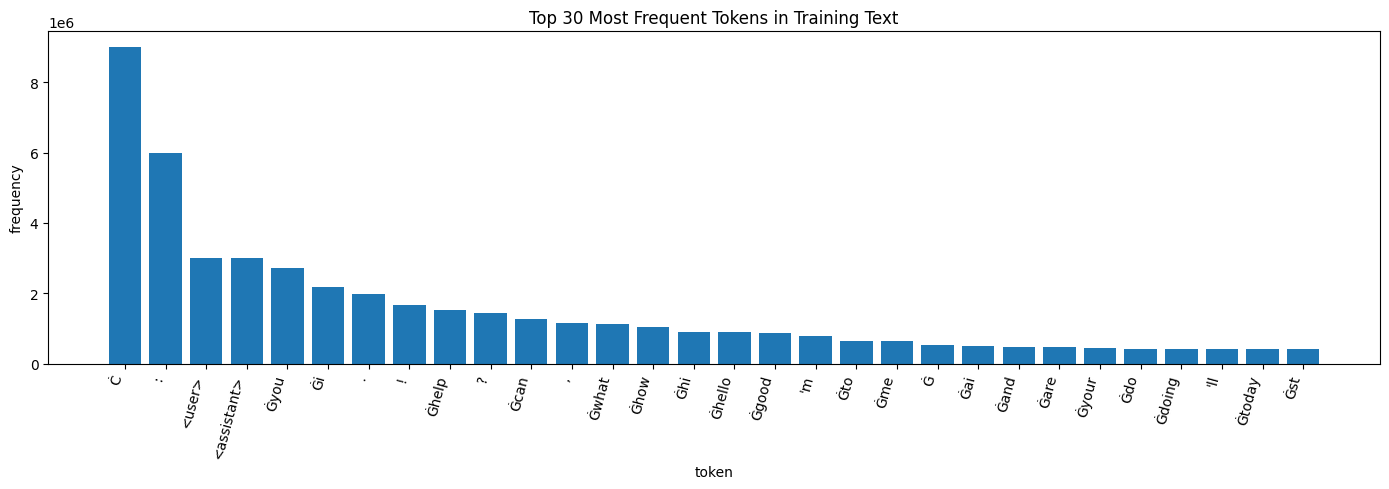

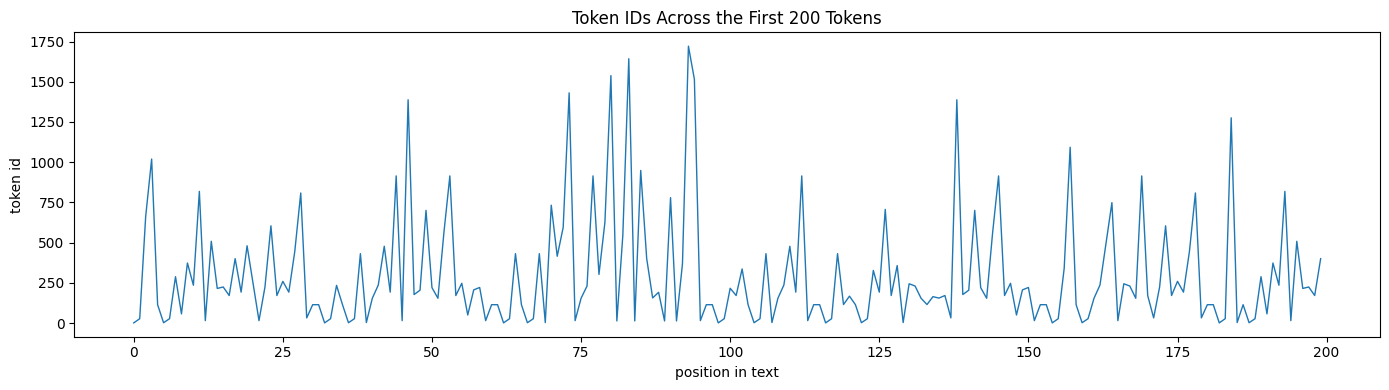

In [96]:
id_to_token = {token_id: token for token, token_id in tokenizer.tokenizer.get_vocab().items()}
token_counts = Counter(encoded.tolist())
top_tokens = token_counts.most_common(30)

labels = [id_to_token[token_id] for token_id, _ in top_tokens]
counts = [count for _, count in top_tokens]

plt.figure(figsize=(14, 5))
plt.bar(range(len(labels)), counts)
plt.xticks(range(len(labels)), labels, rotation=75, ha="right")
plt.title("Top 30 Most Frequent Tokens in Training Text")
plt.xlabel("token")
plt.ylabel("frequency")
plt.tight_layout()
plt.show()

sample_token_ids = encoded[:200].tolist()
plt.figure(figsize=(14, 4))
plt.plot(sample_token_ids, linewidth=1)
plt.title("Token IDs Across the First 200 Tokens")
plt.xlabel("position in text")
plt.ylabel("token id")
plt.tight_layout()
plt.show()

## 6. Train/Validation Split and Batches

This section splits the encoded dataset into training and validation parts. The model learns from the training split, while the validation split is used to estimate how well the model is generalizing to text it is not directly optimizing on. The `make_batch` function randomly samples context windows of length `BLOCK_SIZE`; each input sequence `x` is paired with a target sequence `y` shifted one token to the right. This next-token prediction setup is the core training objective for GPT-style language models.

In [97]:
split_index = int(0.9 * len(encoded))
train_data = encoded[:split_index]
val_data = encoded[split_index:]


def make_batch(data):
    starts = torch.randint(len(data) - BLOCK_SIZE, (BATCH_SIZE,))
    x = torch.stack([data[start : start + BLOCK_SIZE] for start in starts])
    y = torch.stack([data[start + 1 : start + BLOCK_SIZE + 1] for start in starts])
    return x.to(DEVICE), y.to(DEVICE)


x_batch, y_batch = make_batch(train_data)
print("x shape:", x_batch.shape)
print("y shape:", y_batch.shape)
print("sample input:")
print(tokenizer.decode(x_batch[0].tolist()))
print("sample target:")
print(tokenizer.decode(y_batch[0].tolist()))

x shape: torch.Size([16, 128])
y shape: torch.Size([16, 128])
sample input:
: how are you doing
<assistant>: absolutely. tell me what you want to work on. i can help with coding, cloud, databases, ai, or general questions.

<user>: can you help me
<assistant>: hello! i'm here to help.

<user>: good afternoon
<assistant>: hello! what would you like to do today? share the problem and i'll help you solve it.

<user>: how are you doing
<assistant>: hi there! how can i help?

<user>: hello there
<assistant>: good to
sample target:
 how are you doing
<assistant>: absolutely. tell me what you want to work on. i can help with coding, cloud, databases, ai, or general questions.

<user>: can you help me
<assistant>: hello! i'm here to help.

<user>: good afternoon
<assistant>: hello! what would you like to do today? share the problem and i'll help you solve it.

<user>: how are you doing
<assistant>: hi there! how can i help?

<user>: hello there
<assistant>: good to see


## 7. Causal Self-Attention

This section implements causal self-attention, the mechanism that lets each token decide which previous tokens are useful for predicting the next token. The input is projected into query, key, and value vectors. Queries compare against keys to produce attention scores, and those scores decide how much each value vector contributes to the output. The causal mask prevents a token from looking ahead at future tokens, which keeps training aligned with real generation. This section also records query/key metrics such as query norm, key norm, attention entropy, and max attention probability so you can monitor how attention behaves during training.

In [98]:
class CausalSelfAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.key = nn.Linear(N_EMBD, N_EMBD, bias=False)
        self.query = nn.Linear(N_EMBD, N_EMBD, bias=False)
        self.value = nn.Linear(N_EMBD, N_EMBD, bias=False)
        self.proj = nn.Linear(N_EMBD, N_EMBD)
        self.dropout = nn.Dropout(DROPOUT)
        self.last_metrics = {}
        self.register_buffer("tril", torch.tril(torch.ones(BLOCK_SIZE, BLOCK_SIZE)))

    def forward(self, x):
        batch, time, channels = x.shape
        head_size = channels // N_HEAD

        k = self.key(x).view(batch, time, N_HEAD, head_size).transpose(1, 2)
        q = self.query(x).view(batch, time, N_HEAD, head_size).transpose(1, 2)
        v = self.value(x).view(batch, time, N_HEAD, head_size).transpose(1, 2)

        weights = q @ k.transpose(-2, -1) * head_size**-0.5
        weights = weights.masked_fill(self.tril[:time, :time] == 0, float("-inf"))
        attention_probs = F.softmax(weights, dim=-1)

        with torch.no_grad():
            entropy = -(attention_probs * (attention_probs + 1e-9).log()).sum(dim=-1).mean()
            self.last_metrics = {
                "query_norm": q.norm(dim=-1).mean().item(),
                "key_norm": k.norm(dim=-1).mean().item(),
                "attention_entropy": entropy.item(),
                "attention_entropy_ratio": (entropy / math.log(time)).item() if time > 1 else 0.0,
                "attention_max_prob": attention_probs.max(dim=-1).values.mean().item(),
            }

        weights = self.dropout(attention_probs)

        out = weights @ v
        out = out.transpose(1, 2).contiguous().view(batch, time, channels)
        return self.dropout(self.proj(out))

## 8. Transformer Block

This section combines attention with a feed-forward network to create one transformer block. Each block uses residual connections so information can flow through the model more easily, and layer normalization helps keep activations stable. The attention part mixes information across positions in the sequence, while the feed-forward part transforms each position independently. Stacking several of these blocks gives the model enough depth to learn richer conversational patterns.

In [99]:
class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(N_EMBD, 4 * N_EMBD),
            nn.GELU(),
            nn.Linear(4 * N_EMBD, N_EMBD),
            nn.Dropout(DROPOUT),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.attention = CausalSelfAttention()
        self.feed_forward = FeedForward()
        self.layer_norm_1 = nn.LayerNorm(N_EMBD)
        self.layer_norm_2 = nn.LayerNorm(N_EMBD)

    def forward(self, x):
        x = x + self.attention(self.layer_norm_1(x))
        x = x + self.feed_forward(self.layer_norm_2(x))
        return x

## 9. Tiny GPT Model

This section defines the complete tiny GPT model. Token embeddings turn token IDs into vectors, position embeddings tell the model where each token appears in the context window, transformer blocks process the sequence, and the final linear head predicts the next-token probabilities. When target tokens are provided, the model calculates cross-entropy loss, which measures how wrong its next-token predictions are. The `generate` method uses the model's predicted probabilities to sample new tokens one at a time.

In [100]:
class TinyGPT(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, N_EMBD)
        self.position_embedding = nn.Embedding(BLOCK_SIZE, N_EMBD)
        self.blocks = nn.Sequential(*[TransformerBlock() for _ in range(N_LAYER)])
        self.layer_norm = nn.LayerNorm(N_EMBD)
        self.lm_head = nn.Linear(N_EMBD, vocab_size)

    def forward(self, input_ids, targets=None):
        batch, time = input_ids.shape
        token_emb = self.token_embedding(input_ids)
        pos_emb = self.position_embedding(torch.arange(time, device=DEVICE))
        x = token_emb + pos_emb
        x = self.blocks(x)
        x = self.layer_norm(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            batch, time, channels = logits.shape
            logits_flat = logits.view(batch * time, channels)
            targets_flat = targets.view(batch * time)
            loss = F.cross_entropy(logits_flat, targets_flat)

        return logits, loss

    def attention_metrics(self):
        layer_metrics = [
            block.attention.last_metrics
            for block in self.blocks
            if block.attention.last_metrics
        ]
        if not layer_metrics:
            return {}

        return {
            key: sum(metrics[key] for metrics in layer_metrics) / len(layer_metrics)
            for key in layer_metrics[0]
        }

    @torch.no_grad()
    def generate(self, input_ids, max_new_tokens):
        for _ in range(max_new_tokens):
            context = input_ids[:, -BLOCK_SIZE:]
            logits, _ = self(context)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            input_ids = torch.cat((input_ids, next_id), dim=1)
        return input_ids


model = TinyGPT(tokenizer.vocab_size).to(DEVICE)
print(model)
print("parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

TinyGPT(
  (token_embedding): Embedding(2000, 128)
  (position_embedding): Embedding(128, 128)
  (blocks): Sequential(
    (0): TransformerBlock(
      (attention): CausalSelfAttention(
        (key): Linear(in_features=128, out_features=128, bias=False)
        (query): Linear(in_features=128, out_features=128, bias=False)
        (value): Linear(in_features=128, out_features=128, bias=False)
        (proj): Linear(in_features=128, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (feed_forward): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=128, out_features=512, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=512, out_features=128, bias=True)
          (3): Dropout(p=0.1, inplace=False)
        )
      )
      (layer_norm_1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (layer_norm_2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    )
    (1): Transform

## 10. Evaluation and Training

This section trains the model with backpropagation. For each batch, the model predicts the next token, computes loss, calls `loss.backward()` to calculate gradients, clips the gradient norm with `GRAD_CLIP` to avoid unstable updates, and then updates weights with AdamW. At evaluation intervals, the notebook estimates training and validation loss, records gradient norm, and records query/key attention metrics. Watching these values helps you see whether the model is learning, overfitting, or becoming unstable.

In [101]:
@torch.no_grad()
def estimate_loss(model, train_data, val_data):
    model.eval()
    losses = {}
    for split, data in [("train", train_data), ("val", val_data)]:
        split_losses = []
        for _ in range(20):
            x, y = make_batch(data)
            _, loss = model(x, y)
            split_losses.append(loss.item())
        losses[split] = sum(split_losses) / len(split_losses)
    model.train()
    return losses


@torch.no_grad()
def estimate_attention_metrics(model, data):
    model.eval()
    x, y = make_batch(data)
    model(x, y)
    metrics = model.attention_metrics()
    model.train()
    return metrics


def train_model(model):
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

    print(f"device: {DEVICE}")
    print(f"characters in dataset: {len(text)}")
    print(f"vocab size: {tokenizer.vocab_size}")
    print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")

    history = {
        "step": [],
        "train_loss": [],
        "val_loss": [],
        "grad_norm": [],
        "query_norm": [],
        "key_norm": [],
        "attention_entropy_ratio": [],
        "attention_max_prob": [],
    }
    latest_grad_norm = 0.0

    for step in range(MAX_ITERS + 1):
        if step % EVAL_INTERVAL == 0:
            losses = estimate_loss(model, train_data, val_data)
            attention_metrics = estimate_attention_metrics(model, val_data)
            print(
                f"step {step:04d} | "
                f"train loss {losses['train']:.4f} | "
                f"val loss {losses['val']:.4f} | "
                f"grad norm {latest_grad_norm:.3f} | "
                f"q norm {attention_metrics.get('query_norm', 0):.3f} | "
                f"k norm {attention_metrics.get('key_norm', 0):.3f} | "
                f"attn entropy {attention_metrics.get('attention_entropy_ratio', 0):.3f} | "
                f"max attn {attention_metrics.get('attention_max_prob', 0):.3f}"
            )
            history["step"].append(step)
            history["train_loss"].append(losses["train"])
            history["val_loss"].append(losses["val"])
            history["grad_norm"].append(latest_grad_norm)
            history["query_norm"].append(attention_metrics.get("query_norm", 0.0))
            history["key_norm"].append(attention_metrics.get("key_norm", 0.0))
            history["attention_entropy_ratio"].append(attention_metrics.get("attention_entropy_ratio", 0.0))
            history["attention_max_prob"].append(attention_metrics.get("attention_max_prob", 0.0))

        x, y = make_batch(train_data)
        _, loss = model(x, y)
        optimizer.zero_grad(set_to_none=True)
        # Backpropagation: compute gradients, keep them stable, then update weights.
        loss.backward()
        latest_grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP).item()
        optimizer.step()

    return model, history


model, history = train_model(model)

device: cpu
characters in dataset: 204278808
vocab size: 2000
parameters: 1,322,192
step 0000 | train loss 7.8361 | val loss 7.8326 | grad norm 0.000 | q norm 3.244 | k norm 3.242 | attn entropy 0.789 | max attn 0.065
step 0500 | train loss 0.4878 | val loss 0.4585 | grad norm 0.565 | q norm 5.047 | k norm 5.758 | attn entropy 0.624 | max attn 0.205
step 1000 | train loss 0.2965 | val loss 0.3072 | grad norm 0.308 | q norm 5.588 | k norm 6.428 | attn entropy 0.570 | max attn 0.265
step 1500 | train loss 0.2854 | val loss 0.2970 | grad norm 0.174 | q norm 5.715 | k norm 6.590 | attn entropy 0.559 | max attn 0.277
step 2000 | train loss 0.2798 | val loss 0.2969 | grad norm 0.179 | q norm 5.857 | k norm 6.656 | attn entropy 0.548 | max attn 0.290
step 2500 | train loss 0.2755 | val loss 0.2931 | grad norm 0.147 | q norm 5.951 | k norm 6.681 | attn entropy 0.544 | max attn 0.296
step 3000 | train loss 0.2778 | val loss 0.2948 | grad norm 0.185 | q norm 5.970 | k norm 6.816 | attn entropy 0

## 11. Training Loss Plot

This section plots the training history collected during optimization. The loss plot shows whether training loss and validation loss are decreasing over time. The gradient norm plot shows how large gradients were before clipping, which helps diagnose exploding gradients. The query/key attention metric plot gives a rough view of how the attention mechanism changes during learning. Together, these charts make training behavior easier to understand than printed logs alone.

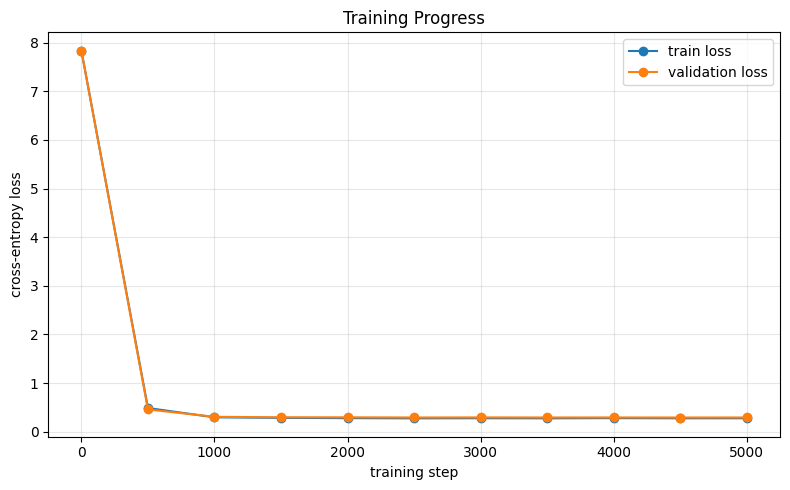

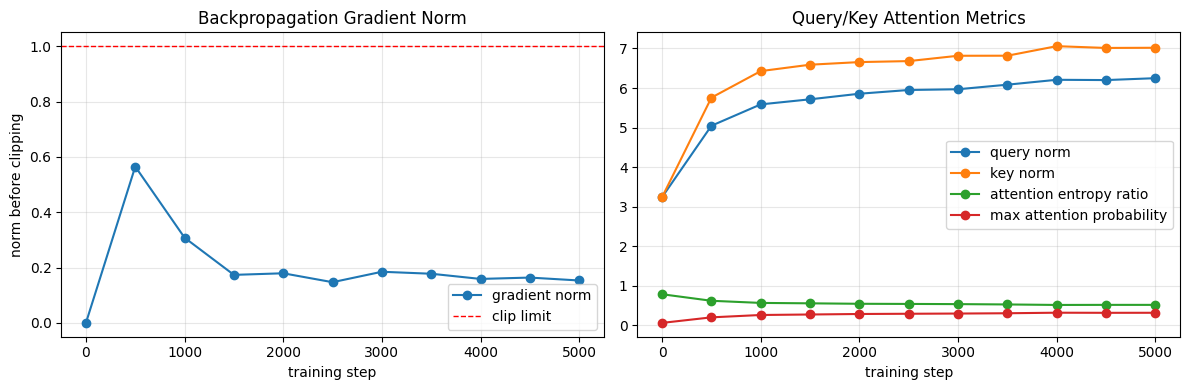

In [102]:
plt.figure(figsize=(8, 5))
plt.plot(history["step"], history["train_loss"], marker="o", label="train loss")
plt.plot(history["step"], history["val_loss"], marker="o", label="validation loss")
plt.title("Training Progress")
plt.xlabel("training step")
plt.ylabel("cross-entropy loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["step"], history["grad_norm"], marker="o", label="gradient norm")
axes[0].axhline(GRAD_CLIP, color="red", linestyle="--", linewidth=1, label="clip limit")
axes[0].set_title("Backpropagation Gradient Norm")
axes[0].set_xlabel("training step")
axes[0].set_ylabel("norm before clipping")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history["step"], history["query_norm"], marker="o", label="query norm")
axes[1].plot(history["step"], history["key_norm"], marker="o", label="key norm")
axes[1].plot(history["step"], history["attention_entropy_ratio"], marker="o", label="attention entropy ratio")
axes[1].plot(history["step"], history["attention_max_prob"], marker="o", label="max attention probability")
axes[1].set_title("Query/Key Attention Metrics")
axes[1].set_xlabel("training step")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 12. Save Checkpoint

This section saves the trained model weights and important configuration values to a checkpoint file. Saving a checkpoint means you do not need to retrain the model every time you want to chat with it. The checkpoint stores the model state dictionary, tokenizer path, and architecture settings needed to rebuild the same model shape later.

In [103]:
CHECKPOINT_DIR.mkdir(exist_ok=True)
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "tokenizer_path": str(TOKENIZER_PATH),
        "config": {
            "batch_size": BATCH_SIZE,
            "block_size": BLOCK_SIZE,
            "n_embd": N_EMBD,
            "n_head": N_HEAD,
            "n_layer": N_LAYER,
        },
    },
    CHECKPOINT_PATH,
)

print("saved checkpoint:", CHECKPOINT_PATH)

saved checkpoint: /Users/abhishek/MLCourse/GenAI/gpt_from_scratch_chatbot/checkpoints/tiny_chatbot_combined.pt


## 13. Chat With the Trained Model

This section provides a small helper for chatting with the trained model. It formats the user's message using the same `<user>:` and `<assistant>:` pattern seen during training, encodes the prompt, generates new tokens, decodes them back into text, and extracts only the assistant response. The quality of the answers depends heavily on dataset size, training time, and model capacity, so this tiny model is mainly for learning how the full pipeline works.

In [116]:
def chat_once(model, tokenizer, user_message, max_new_tokens=300):
    prompt = f"<user>: {user_message.lower()}\n<assistant>:"
    input_ids = torch.tensor([tokenizer.encode(prompt)], dtype=torch.long).to(DEVICE)
    output_ids = model.generate(input_ids, max_new_tokens=max_new_tokens)[0].tolist()
    generated = tokenizer.decode(output_ids)
    answer = generated.split("<assistant>:")[-1]
    answer = answer.split("<user>:")[0]
    return answer.strip()


for question in ["hi", "thanks"]:
    print("user:", question)
    print("assistant:", chat_once(model, tokenizer, question))
    print()

user: hi
assistant: i'm doing well.

user: thanks
assistant: you're welcome.



## 14. Load Checkpoint Later

This section shows how to reload a saved checkpoint for future use. It loads the tokenizer, rebuilds the tiny GPT architecture with the correct vocabulary size, restores the saved model weights, and switches the model into evaluation mode. After this step, you can call the same chat helper without retraining from scratch.

In [117]:
def load_checkpoint():
    if not CHECKPOINT_PATH.exists():
        raise FileNotFoundError(f"No checkpoint found at {CHECKPOINT_PATH}.")

    checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
    loaded_tokenizer = ChatTokenizer(Tokenizer.from_file(checkpoint["tokenizer_path"]))
    loaded_model = TinyGPT(loaded_tokenizer.vocab_size).to(DEVICE)
    loaded_model.load_state_dict(checkpoint["model_state_dict"])
    loaded_model.eval()
    return loaded_model, loaded_tokenizer


loaded_model, loaded_tokenizer = load_checkpoint()
chat_once(loaded_model, loaded_tokenizer, "hello there")

'hi there! how can i help?'

## 15. Continue Training on Updated Greeting Data

This final section is for appending more examples to `greeting_conversations.json` and continuing training from the saved checkpoint. After you add more JSONL lines to the dataset, run this cell to reload the trained model, rebuild batches from the updated greeting data, measure next-token validation accuracy before training, train for more steps, measure accuracy again, and save the improved checkpoint. The accuracy here is token-level accuracy, so it measures how often the model predicts the exact next token in the validation batches.

In [109]:
CONTINUE_TRAIN_ITERS = 1000
CONTINUE_EVAL_INTERVAL = 100


@torch.no_grad()
def estimate_token_accuracy(model, data, num_batches=20):
    model.eval()
    correct = 0
    total = 0

    for _ in range(num_batches):
        x, y = make_batch(data)
        logits, _ = model(x, y)
        predictions = logits.argmax(dim=-1)
        correct += (predictions == y).sum().item()
        total += y.numel()

    model.train()
    return correct / total if total else 0.0


def continue_training_from_checkpoint(extra_iters=CONTINUE_TRAIN_ITERS):
    continued_model, continued_tokenizer = load_checkpoint()
    continued_model.train()

    updated_text = load_text()
    updated_encoded = torch.tensor(continued_tokenizer.encode(updated_text), dtype=torch.long)
    updated_split_index = int(0.9 * len(updated_encoded))
    updated_train_data = updated_encoded[:updated_split_index]
    updated_val_data = updated_encoded[updated_split_index:]

    before_loss = estimate_loss(continued_model, updated_train_data, updated_val_data)
    before_accuracy = estimate_token_accuracy(continued_model, updated_val_data)
    print(f"before extra training | val loss {before_loss['val']:.4f} | val token accuracy {before_accuracy:.4f}")

    optimizer = torch.optim.AdamW(continued_model.parameters(), lr=LEARNING_RATE)
    for step in range(1, extra_iters + 1):
        x, y = make_batch(updated_train_data)
        _, loss = continued_model(x, y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        grad_norm = torch.nn.utils.clip_grad_norm_(continued_model.parameters(), GRAD_CLIP).item()
        optimizer.step()

        if step % CONTINUE_EVAL_INTERVAL == 0 or step == extra_iters:
            current_accuracy = estimate_token_accuracy(continued_model, updated_val_data, num_batches=5)
            print(
                f"extra step {step:04d} | "
                f"loss {loss.item():.4f} | "
                f"grad norm {grad_norm:.3f} | "
                f"val token accuracy {current_accuracy:.4f}"
            )

    after_loss = estimate_loss(continued_model, updated_train_data, updated_val_data)
    after_accuracy = estimate_token_accuracy(continued_model, updated_val_data)
    print(f"after extra training | val loss {after_loss['val']:.4f} | val token accuracy {after_accuracy:.4f}")

    torch.save(
        {
            "model_state_dict": continued_model.state_dict(),
            "tokenizer_path": str(TOKENIZER_PATH),
            "config": {
                "batch_size": BATCH_SIZE,
                "block_size": BLOCK_SIZE,
                "n_embd": N_EMBD,
                "n_head": N_HEAD,
                "n_layer": N_LAYER,
            },
        },
        CHECKPOINT_PATH,
    )
    print("updated checkpoint saved:", CHECKPOINT_PATH)
    return continued_model, continued_tokenizer, before_accuracy, after_accuracy


# Add more JSONL conversations to greeting_conversations.json, then run this line.
continued_model, continued_tokenizer, before_accuracy, after_accuracy = continue_training_from_checkpoint(extra_iters=CONTINUE_TRAIN_ITERS)

before extra training | val loss 0.2919 | val token accuracy 0.8740
extra step 0100 | loss 0.2708 | grad norm 0.162 | val token accuracy 0.8753
extra step 0200 | loss 0.2917 | grad norm 0.176 | val token accuracy 0.8725
extra step 0300 | loss 0.2667 | grad norm 0.145 | val token accuracy 0.8752
extra step 0400 | loss 0.2859 | grad norm 0.125 | val token accuracy 0.8748
extra step 0500 | loss 0.2685 | grad norm 0.181 | val token accuracy 0.8765
extra step 0600 | loss 0.2761 | grad norm 0.138 | val token accuracy 0.8752
extra step 0700 | loss 0.2617 | grad norm 0.130 | val token accuracy 0.8767
extra step 0800 | loss 0.2773 | grad norm 0.189 | val token accuracy 0.8767
extra step 0900 | loss 0.2656 | grad norm 0.141 | val token accuracy 0.8755
extra step 1000 | loss 0.2618 | grad norm 0.149 | val token accuracy 0.8741
after extra training | val loss 0.2940 | val token accuracy 0.8749
updated checkpoint saved: /Users/abhishek/MLCourse/GenAI/gpt_from_scratch_chatbot/checkpoints/tiny_chatbo

In [111]:
def load_checkpoint():
    if not CHECKPOINT_PATH.exists():
        raise FileNotFoundError(f"No checkpoint found at {CHECKPOINT_PATH}.")

    checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
    loaded_tokenizer = ChatTokenizer(Tokenizer.from_file(checkpoint["tokenizer_path"]))
    loaded_model = TinyGPT(loaded_tokenizer.vocab_size).to(DEVICE)
    loaded_model.load_state_dict(checkpoint["model_state_dict"])
    loaded_model.eval()
    return loaded_model, loaded_tokenizer


loaded_model, loaded_tokenizer = load_checkpoint()
chat_once(loaded_model, loaded_tokenizer, "What's up")

'good to see you! what can i help you with? what would you like to learn today'